<a href="https://colab.research.google.com/github/youelfissha23-boop/parkinsons-voice-screening/blob/main/notebooks/01_leakage_safe_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [56]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import make_scorer, recall_score
from pathlib import Path
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt
from xgboost import XGBClassifier

LOCAL_PATH = Path("../data/parkinsons.data")
URL = "https://raw.githubusercontent.com/youelfissha23-boop/parkinsons-voice-screening/main/data/parkinsons.data"

df = pd.read_csv(LOCAL_PATH if LOCAL_PATH.exists() else URL)
print(df.shape)
display(df.head())
df.info()

(195, 24)


,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              195 non-null    object 
 1   MDVP:Fo(Hz)       195 non-null    float64
 2   MDVP:Fhi(Hz)      195 non-null    float64
 3   MDVP:Flo(Hz)      195 non-null    float64
 4   MDVP:Jitter(%)    195 non-null    float64
 5   MDVP:Jitter(Abs)  195 non-null    float64
 6   MDVP:RAP          195 non-null    float64
 7   MDVP:PPQ          195 non-null    float64
 8   Jitter:DDP        195 non-null    float64
 9   MDVP:Shimmer      195 non-null    float64
 10  MDVP:Shimmer(dB)  195 non-null    float64
 11  Shimmer:APQ3      195 non-null    float64
 12  Shimmer:APQ5      195 non-null    float64
 13  MDVP:APQ          195 non-null    float64
 14  Shimmer:DDA       195 non-null    float64
 15  NHR               195 non-null    float64
 16  HNR               195 non-null    float64
 1

In [57]:
print(df["status"].value_counts())
print(df["status"].value_counts(normalize=True))

status
1    147
0     48
Name: count, dtype: int64
status
1    0.753846
0    0.246154
Name: proportion, dtype: float64


In [58]:
df["subject"] = df["name"].str.extract(r"(S\d+)")
df["subject"].nunique()
df.groupby("subject")["status"].nunique().max()

1

In [59]:
y = df["status"]
X = df.drop(columns=["name","subject","status"])
groups = df["subject"]

In [60]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
leaky = make_pipeline(StandardScaler(), RandomForestClassifier(random_state=42))
leaky.fit(X_tr, y_tr)
y_pred = leaky.predict(X_te)
print(accuracy_score(y_te, y_pred))

0.9487179487179487


In [61]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

In [62]:
print("Overlap of people:", set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))

Overlap of people: set()


In [63]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Baseline accuracy:", accuracy_score(y_test, dummy.predict(X_test)))

Baseline accuracy: 0.7209302325581395


In [64]:
model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
model.fit(X_train, y_train)
preds = model.predict(X_test)
print("Grouped-split accuracy:", accuracy_score(y_test, preds))
print(confusion_matrix(y_test, preds))
print(classification_report(y_test, preds))

Grouped-split accuracy: 0.5813953488372093
[[ 3  9]
 [ 9 22]]
              precision    recall  f1-score   support

           0       0.25      0.25      0.25        12
           1       0.71      0.71      0.71        31

    accuracy                           0.58        43
   macro avg       0.48      0.48      0.48        43
weighted avg       0.58      0.58      0.58        43



In [65]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)),
    "SVM": make_pipeline(StandardScaler(), SVC(class_weight="balanced", probability=True)),
    "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(class_weight="balanced", random_state=42)),
}
cv = GroupKFold(n_splits=5)
for name, m in models.items():
    r = cross_validate(m, X, y, groups=groups, cv=cv,
                       scoring=["accuracy", "balanced_accuracy", "recall"])
    print(f"{name:20s} acc={r['test_accuracy'].mean():.3f}  "
          f"balanced_acc={r['test_balanced_accuracy'].mean():.3f}  "
          f"recall={r['test_recall'].mean():.3f}")

Logistic Regression  acc=0.709  balanced_acc=0.635  recall=0.770
SVM                  acc=0.650  balanced_acc=0.586  recall=0.717
Random Forest        acc=0.760  balanced_acc=0.615  recall=0.901


In [66]:
demo = pd.DataFrame({"person": list("AAABBBCCCDDD"), "value": range(12)})
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0)
tr, te = next(splitter.split(demo, groups=demo["person"]))
print(tr)
print(te)
print(demo.iloc[te])

[ 0  1  2  3  4  5  9 10 11]
[6 7 8]
  person  value
6      C      6
7      C      7
8      C      8


In [67]:
cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=0)

for fold, (train_idx, text_idx) in enumerate(cv.split(X, y, groups)):
  test_people = sorted(set(groups.iloc[test_idx]))
  healthy_people = groups.iloc[test_idx][y.iloc[test_idx] == 0].nunique()
  print(f"Fold {fold}: {len(train_idx)} train rows, {len(test_idx)} test rows, "
        f"{len(test_people)} test people, of whom {healthy_people} healthy")

Fold 0: 147 train rows, 43 test rows, 7 test people, of whom 2 healthy
Fold 1: 145 train rows, 43 test rows, 7 test people, of whom 2 healthy
Fold 2: 146 train rows, 43 test rows, 7 test people, of whom 2 healthy
Fold 3: 147 train rows, 43 test rows, 7 test people, of whom 2 healthy


In [68]:
probs = model.predict_proba(X_test)
print(probs.shape)
print(probs[:5])
print(probs[:5].sum(axis=1))

(43, 2)
[[0.06588937 0.93411063]
 [0.11238249 0.88761751]
 [0.1696087  0.8303913 ]
 [0.05392511 0.94607489]
 [0.51310424 0.48689576]]
[1. 1. 1. 1. 1.]


In [69]:
# Initialize an array to hold out-of-fold predictions
oof_proba = np.full(len(X), np.nan)
# Define the cross-validation splitter
cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=0)
# Iterate through the folds
for train_idx, test_idx in cv.split(X, y, groups):
    fold_model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
    # Split data
    X_train_fold, X_test_fold = X.iloc[train_idx], X.iloc[test_idx]
    y_train_fold, y_test_fold = y.iloc[train_idx], y.iloc[test_idx]
    # Fit model on training fold
    fold_model.fit(X_train_fold, y_train_fold)
    # Predict on test fold and store in the respective indices
    oof_proba[test_idx] = fold_model.predict_proba(X_test_fold)[:, 1]

oof_pred = (oof_proba >= 0.5).astype(int)
# Evaluation
print("Empty slots left:", np.isnan(oof_proba).sum())
print(oof_proba[:5])
print("Out-of-Fold Accuracy:", accuracy_score(y, oof_pred))
oof_pred

Empty slots left: 0
[0.99991586 0.99999596 0.99997379 0.99999343 0.99996683]
Out-of-Fold Accuracy: 0.7487179487179487


array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1,
       1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1])

In [70]:
print(confusion_matrix(y, oof_pred))

[[ 26  22]
 [ 27 120]]


In [71]:
#step D
tn, fp, fn, tp = confusion_matrix(y, oof_pred).ravel()

recall = tp/ (tp + fn)
specificity = tn/ (tn + fp)
print(f"recall: {recall}, specificity: {specificity}")

recall: 0.8163265306122449, specificity: 0.5416666666666666


In [72]:
#step E
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
  pred = (oof_proba >= t).astype(int)
  tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
  recall = tp/ (tp + fn)
  specificity = tn/ (tn + fp)
  print(f"recall: {recall}")
  print(f"specificity: {specificity}")
  print("flagged:", pred.sum())

recall: 0.8571428571428571
specificity: 0.4791666666666667
flagged: 151
recall: 0.8299319727891157
specificity: 0.5
flagged: 146
recall: 0.8163265306122449
specificity: 0.5416666666666666
flagged: 142
recall: 0.782312925170068
specificity: 0.5416666666666666
flagged: 137
recall: 0.7346938775510204
specificity: 0.5625
flagged: 129
recall: 0.6666666666666666
specificity: 0.5833333333333334
flagged: 118


In [73]:
fn_mask = ~(oof_pred == 1) & (y == 1)
print(fn_mask.sum())

27


In [74]:
print(np.percentile(oof_proba, [5, 25, 50, 75, 95]).round(4))

print("median score, sick recordings: ", np.median(oof_proba[(y == 1).values]))
print("median score, healthy recordings: ", np.median(oof_proba[(y == 0).values]))

[0.0309 0.4192 0.8996 0.9855 1.    ]
median score, sick recordings:  0.915415335370133
median score, healthy recordings:  0.41553158104327986


In [75]:
lr_auc = roc_auc_score(y, oof_proba)
lr_fpr, lr_tpr, thr = roc_curve(y, oof_proba)

r_probs = [0 for _ in range(len(y))]
r_auc = roc_auc_score(y, r_probs)
r_fpr, r_tpr, _ = roc_curve(y, r_probs)

print("Random AUC:", round(r_auc, 3))
print("AUC:", round(lr_auc, 3))
print(f"model (AUC= {lr_auc:.2f})")

Random AUC: 0.5
AUC: 0.698
model (AUC= 0.70)


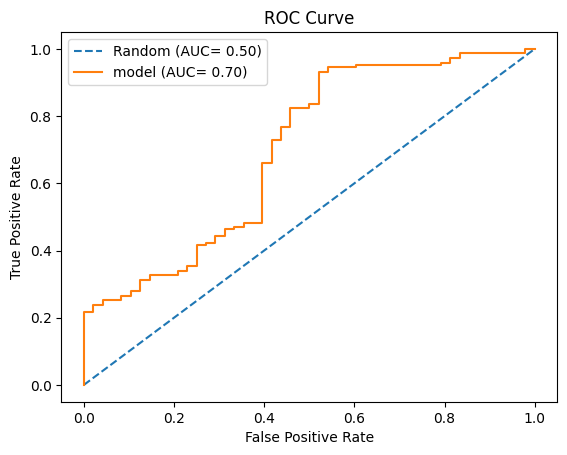

In [76]:
plt.plot(r_fpr, r_tpr, linestyle="--", label=f"Random (AUC= {r_auc:.2f})")
plt.plot(lr_fpr, lr_tpr, label=f"model (AUC= {lr_auc:.2f})")

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

[13:53:44] INFO: /__w/xgboost/xgboost/src/data/iterative_dmatrix.cc:56: Finished constructing the `IterativeDMatrix`: (152, 22, 3344).


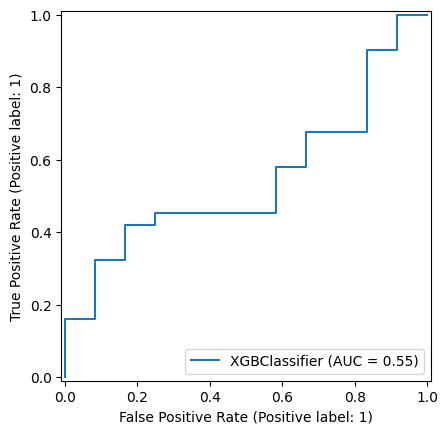

Accuracy: 0.7209302325581395


In [77]:
from sklearn.metrics import RocCurveDisplay
xg = XGBClassifier(learning_rate=0.1, max_depth=20, verbosity=2, random_state=42)
xg.fit(X_train, y_train)
y_pred = xg.predict(X_test)

# Using the modern replacement to plot the ROC Curve
RocCurveDisplay.from_estimator(xg, X_test, y_test)
plt.show()
print("Accuracy:", accuracy_score(y_test, y_pred))

In [78]:
oof_proba_lr = np.full(len(X), np.nan)
oof_proba_rf = np.full(len(X), np.nan)
oof_proba_svm = np.full(len(X), np.nan)
oof_proba_xgb = np.full(len(X), np.nan)

cv = StratifiedGroupKFold(n_splits = 4, shuffle=True, random_state=0)
#straight line
r_probs = [0 for _ in range(len(y))]
r_auc = roc_auc_score(y, r_probs)

for train_idx, test_idx in cv.split(X, y, groups):
    X_train_fold, X_test_fold = X.iloc[train_idx], X.iloc[test_idx]
    y_train_fold, y_test_fold = y.iloc[train_idx], y.iloc[test_idx]

    #Logistic Regression
    lr = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
    lr.fit(X_train_fold, y_train_fold)
    oof_proba_lr[test_idx] = lr.predict_proba(X_test_fold)[:, 1]

    #Random Forest
    rf = make_pipeline(StandardScaler(), RandomForestClassifier(class_weight="balanced", random_state=42))
    rf.fit(X_train_fold, y_train_fold)
    oof_proba_rf[test_idx] = rf.predict_proba(X_test_fold)[:, 1]

    #SVM
    svm = make_pipeline(StandardScaler(), SVC(class_weight="balanced", max_iter=1000, probability=True))
    svm.fit(X_train_fold, y_train_fold)
    oof_proba_svm[test_idx] = svm.predict_proba(X_test_fold)[:, 1]

    #XGBoost Classifier
    xgb = make_pipeline(StandardScaler(), XGBClassifier(learning_rate =0.01, max_depth=3, verbosity=2, random_state=42, subsample=0.7, colsample_bytree=0.9))
    xgb.fit(X_train_fold, y_train_fold)
    oof_proba_xgb[test_idx] = xgb.predict_proba(X_test_fold)[:, 1]

lr_auc = roc_auc_score(y, oof_proba_lr)
rf_auc = roc_auc_score(y, oof_proba_rf)
svm_auc = roc_auc_score(y, oof_proba_svm)
xgb_auc = roc_auc_score(y, oof_proba_xgb)

print(f"Logistic Regression AUC: {lr_auc:.3f}")
print(f"Random Forest AUC: {rf_auc:.3f}")
print(f"SVM AUC: {svm_auc:.3f}")
print(f"XGBoost Classifier AUC: {xgb_auc:.3f}")


[13:53:46] INFO: /__w/xgboost/xgboost/src/data/iterative_dmatrix.cc:56: Finished constructing the `IterativeDMatrix`: (147, 22, 3234).
[13:53:47] INFO: /__w/xgboost/xgboost/src/data/iterative_dmatrix.cc:56: Finished constructing the `IterativeDMatrix`: (145, 22, 3190).
[13:53:48] INFO: /__w/xgboost/xgboost/src/data/iterative_dmatrix.cc:56: Finished constructing the `IterativeDMatrix`: (146, 22, 3212).
[13:53:48] INFO: /__w/xgboost/xgboost/src/data/iterative_dmatrix.cc:56: Finished constructing the `IterativeDMatrix`: (147, 22, 3234).
Logistic Regression AUC: 0.698
Random Forest AUC: 0.808
SVM AUC: 0.660
XGBoost Classifier AUC: 0.782


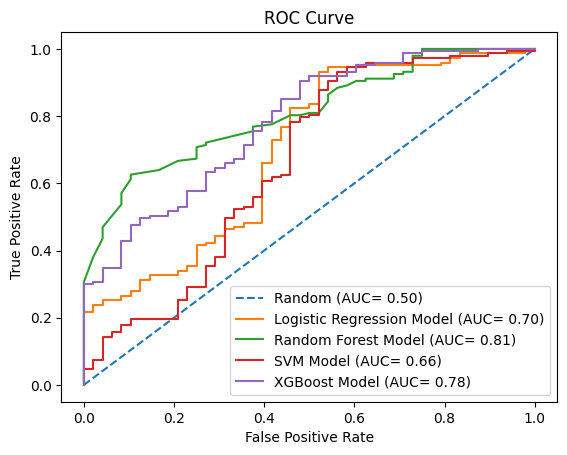

In [79]:
lr_fpr, lr_tpr, thr = roc_curve(y, oof_proba_lr)
rf_fpr, rf_tpr, thr = roc_curve(y, oof_proba_rf)
svm_fpr, svm_tpr, thr = roc_curve(y, oof_proba_svm)
xgb_fpr, xgb_tpr, thr = roc_curve(y, oof_proba_xgb)
r_fpr, r_tpr, _ = roc_curve(y, r_probs)

plt.plot(r_fpr, r_tpr, linestyle="--", label=f"Random (AUC= {r_auc:.2f})")
plt.plot(lr_fpr, lr_tpr, label=f"Logistic Regression Model (AUC= {lr_auc:.2f})")
plt.plot(rf_fpr, rf_tpr, label=f"Random Forest Model (AUC= {rf_auc:.2f})")
plt.plot(svm_fpr, svm_tpr, label=f"SVM Model (AUC= {svm_auc:.2f})")
plt.plot(xgb_fpr, xgb_tpr, label=f"XGBoost Model (AUC= {xgb_auc:.2f})")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

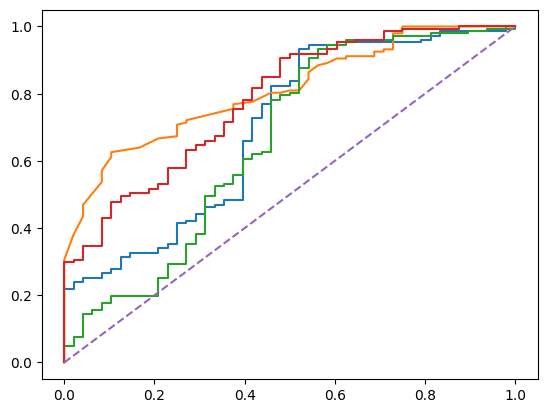

In [80]:
import os

# ROC plot with all four models(looped)
oof = {"Logistic Regression": oof_proba_lr, "Random Forest": oof_proba_rf, "SVM": oof_proba_svm, "XGBoost": oof_proba_xgb}
for name, p in oof.items():
  auc = roc_auc_score(y, p)
  fpr, tpr, thr = roc_curve(y, p)
  plt.plot(fpr, tpr, label=f"{name} Model (AUC= {auc:.2f})")
r_probs = [0 for _ in range(len(y))]
r_auc = roc_auc_score(y, r_probs)
r_fpr, r_tpr, thr = roc_curve(y, r_probs)

plt.plot(r_fpr, r_tpr, linestyle = "--", label=f"Chance Model (AUC= {r_auc:.2f})")

# Ensure the directories exist before saving
os.makedirs("reports/figures", exist_ok=True)
plt.savefig("reports/figures/roc_models.png", dpi=200, bbox_inches="tight")

In [81]:
end = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
  pred = (oof_proba_rf >= t).astype(int)
  tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
  recall = tp/ (tp + fn)
  specificity = tn/ (tn + fp)

  end.append({
      "Threshold": t,
      "Recall": recall,
      "Specificity": specificity,
      "Flagged": pred.sum()
  })

end_df = pd.DataFrame(end).set_index("Threshold")
end_df

,Recall,Specificity,Flagged
Threshold,,,
0.3,0.993197,0.250000,182
0.4,0.979592,0.270833,179
0.5,0.952381,0.270833,175
0.6,0.925170,0.312500,169
0.7,0.904762,0.375000,163
0.8,0.802721,0.541667,140


In [82]:
from sklearn.base import clone

def get_oof_proba(model, X, y, groups, seed=0, n_splits=4):
  """One P(Parkinson's) per recording, from models that never saw that person."""
  cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
  oof = np.full(len(X), np.nan)
  for train_idx, test_idx in cv.split(X, y, groups):
    fold_model = clone(model)
    X_train_fold, X_test_fold = X.iloc[train_idx], X.iloc[test_idx]
    y_train_fold, y_test_fold = y.iloc[train_idx], y.iloc[test_idx]
    fold_model.fit(X_train_fold, y_train_fold)
    oof[test_idx]= fold_model.predict_proba(X_test_fold)[:,1]
  return oof


In [83]:
# Define the models you want to evaluate
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(class_weight="balanced", random_state=42)),
    "SVM": make_pipeline(StandardScaler(), SVC(class_weight="balanced", max_iter=1000, probability=True, random_state=0)),
    "XGBoost": make_pipeline(StandardScaler(), XGBClassifier(learning_rate=0.01, max_depth=3, verbosity=0, random_state=42, subsample=0.7, colsample_bytree=0.9))
}

# Set list of seeds to evaluate
seeds = [0, 42, 123, 999, 2026]
results = []

# Run the multi-seed evaluation loop
for model_name, model in models.items():
    auc_scores = []
    for seed in seeds:
        # Get Out-of-Fold probabilities using your helper function
        oof_probs = get_oof_proba(model, X, y, groups, seed=seed, n_splits=4)
        # Calculate AUC for this run
        auc = roc_auc_score(y, oof_probs)
        auc_scores.append(auc)

    results.append({
        "Model": model_name,
        "Mean AUC": np.mean(auc_scores),
        "Std Dev": np.std(auc_scores),
        "Scores": auc_scores
    })

# Display the aggregated results
results_df = pd.DataFrame(results)
display(results_df.sort_values(by="Mean AUC", ascending=False))

,Model,Mean AUC,Std Dev,Scores
1,Random Forest,0.750213,0.040876,"[0.8083191609977324, 0.747732426303855, 0.6820..."
3,XGBoost,0.735643,0.042008,"[0.7816043083900226, 0.7422052154195011, 0.659..."
0,Logistic Regression,0.728600,0.043021,"[0.6975623582766439, 0.733843537414966, 0.6642..."
2,SVM,0.661820,0.060356,"[0.6401643990929705, 0.695578231292517, 0.5583..."


```markdown
### Person-Level Out-of-Fold AUC Evaluation
To evaluate our models at the person level, we will:
1. Collect the recording-level out-of-fold probability predictions.
2. Group the predictions and ground truths by each unique subject (person) and average them.
3. Compute the ROC AUC on these aggregated person-level scores across multiple seeds.
```

In [84]:
seeds = [0, 42, 123, 999, 2026]
person_results = []

for model_name, model in models.items():
    person_auc_scores = []
    for seed in seeds:
        # 1. Get recording-level Out-of-Fold probabilities
        oof_probs = get_oof_proba(model, X, y, groups, seed=seed, n_splits=4)

        # 2. Create a temporary DataFrame to group by subject (person)
        temp_df = pd.DataFrame({
            'subject': groups,
            'y_true': y,
            'oof_proba': oof_probs
        })

        # Aggregate by taking the mean probability and mean label per person
        # Note: Since all recordings for a single subject share the same status (health/sick),
        # taking the mean of y_true per subject preserves their true label (0 or 1).
        person_df = temp_df.groupby('subject').mean()

        # 3. Calculate AUC on the aggregated person-level scores
        auc = roc_auc_score(person_df['y_true'], person_df['oof_proba'])
        person_auc_scores.append(auc)

    person_results.append({
        "Model": model_name,
        "Mean Person AUC": np.mean(person_auc_scores),
        "Std Dev": np.std(person_auc_scores),
        "Scores": person_auc_scores
    })

# Display the aggregated results
person_results_df = pd.DataFrame(person_results)
display(person_results_df.sort_values(by="Mean Person AUC", ascending=False))

,Model,Mean Person AUC,Std Dev,Scores
3,XGBoost,0.759375,0.052021,"[0.8177083333333334, 0.7916666666666667, 0.666..."
1,Random Forest,0.744792,0.052265,"[0.8333333333333334, 0.7265625, 0.671875, 0.73..."
0,Logistic Regression,0.721875,0.036917,"[0.6770833333333334, 0.7291666666666667, 0.682..."
2,SVM,0.660417,0.058128,"[0.640625, 0.6875, 0.5729166666666666, 0.75, 0..."


In [85]:
cv_leaky = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)
p_leaky = cross_val_predict(models["Random Forest"], X, y, cv=cv_leaky, method="predict_proba")[:, 1]
print("Leaky AUC:", roc_auc_score(y, p_leaky))

Leaky AUC: 0.958687641723356


In [86]:
person_df[person_df["y_true"] == 0].sort_values("oof_proba")

,y_true,oof_proba
subject,,
S10,0.0,0.393877
S42,0.0,0.464210
S17,0.0,0.644679
S07,0.0,0.700698
S50,0.0,0.723915
S49,0.0,0.816675
S13,0.0,0.837871
S43,0.0,0.879123


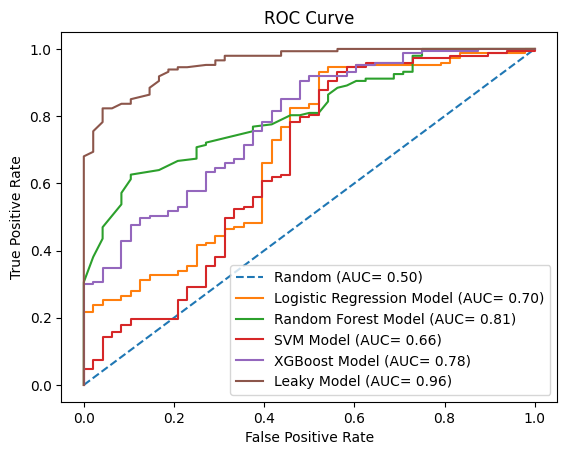

In [87]:
lr_fpr, lr_tpr, thr = roc_curve(y, oof_proba_lr)
rf_fpr, rf_tpr, thr = roc_curve(y, oof_proba_rf)
svm_fpr, svm_tpr, thr = roc_curve(y, oof_proba_svm)
xgb_fpr, xgb_tpr, thr = roc_curve(y, oof_proba_xgb)
r_fpr, r_tpr, _ = roc_curve(y, r_probs)
leaky_fpr, leaky_tpr, _ = roc_curve(y, p_leaky)

plt.plot(r_fpr, r_tpr, linestyle="--", label=f"Random (AUC= {r_auc:.2f})")
plt.plot(lr_fpr, lr_tpr, label=f"Logistic Regression Model (AUC= {lr_auc:.2f})")
plt.plot(rf_fpr, rf_tpr, label=f"Random Forest Model (AUC= {rf_auc:.2f})")
plt.plot(svm_fpr, svm_tpr, label=f"SVM Model (AUC= {svm_auc:.2f})")
plt.plot(xgb_fpr, xgb_tpr, label=f"XGBoost Model (AUC= {xgb_auc:.2f})")
plt.plot(leaky_fpr, leaky_tpr, label=f"Leaky Model (AUC= {roc_auc_score(y, p_leaky):.2f})")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()